# ЛАБОРАТОРНА РОБОТА № 4

## Візуальний аналіз даних та часові ряди — аналіз у двох середовищах

**Курс:** СК26 «Інтелектуальний аналіз та візуалізація даних»
**Кафедра систем штучного інтелекту, Національний університет «Львівська політехніка»**
**Оцінювання:** 4 бали

---

## Визначення варіанта

Заповніть три поля в клітинці нижче й виконайте обидві службові клітинки —
номер варіанта, ринок і товар визначаться автоматично.

In [1]:
# ── Заповніть три поля ──────────────────────────────────────────
SURNAME_NAME = 'Михальчук Антон'      # прізвище та ім'я
GROUP        = 'ШІ-32'      # шифр групи, наприклад СШІ-31
NUMBER       = 13      # ваш номер за списком групи (1–30)

assert SURNAME_NAME.strip(), 'Впишіть прізвище та ім\'я'
assert GROUP.strip(),        'Впишіть групу'
assert isinstance(NUMBER, int) and 1 <= NUMBER <= 30, 'Номер має бути цілим від 1 до 30'
print('Дані прийнято:', SURNAME_NAME, '|', GROUP, '| номер', NUMBER)

Дані прийнято: Михальчук Антон | ШІ-32 | номер 13


In [2]:
# ── Службова клітинка: визначення варіанта. Змінювати не потрібно ──
import json

VARIANTS = json.load(open('lr4_variants_student.json', encoding='utf-8'))
V = VARIANTS[NUMBER - 1]

MARKET, GOOD, GOOD_UA = V['ринок'], V['товар'], V['товар_укр']

print('=' * 72)
print(f'ВАРІАНТ {V["варіант"]}   ·   {SURNAME_NAME}   ·   {GROUP}')
print('=' * 72)
print()
print(f'   Ринок:  {MARKET}')
print(f'   Товар:  {GOOD_UA}   (у наборі даних: {GOOD})')
print()
print('Далі в роботі користуйтеся змінними MARKET і GOOD —')
print('тоді весь код автоматично працюватиме саме з вашим рядом.')
print()
print('Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців')
print('Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)')

ВАРІАНТ 13   ·   Михальчук Антон   ·   ШІ-32

   Ринок:  Zhytomyr
   Товар:  сир кисломолочний   (у наборі даних: Curd - Retail)

Далі в роботі користуйтеся змінними MARKET і GOOD —
тоді весь код автоматично працюватиме саме з вашим рядом.

Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців
Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)


> ⚠️ Якщо ці дві клітинки не виконано, усі подальші завдання не мають сенсу:
> перевіряти роботу будуть **за вашим варіантом**, а не за тим рядом, який ви оберете самі.

| | |
|---|---|
| **Дата здачі** | |
| **Підпис** | |

---
## Мета роботи

Виконати повний цикл аналізу одного часового ряду **у двох середовищах** — у Python та в Orange —
і пояснити, чому однаково названі метрики в них дають різні числа.

## Вихідні дані

| Файл | Зміст |
|---|---|
| `ціни_україна_2014_2017.csv` | Роздрібні ціни на 25 товарів по 28 ринках України, щомісяця, 03.2014 – 12.2017 |
| `lr4_variants_student.json` | Розподіл варіантів (зчитується автоматично) |
| `ЛР4_помилковий_аналіз.ipynb` | Звіт колеги, який треба відрецензувати (завдання 8) |

Це той самий набір, з яким ми працювали на лекції 4. **Національне середнє в завданнях не використовується** —
ваш ряд це конкретний обласний ринок.

## Що здавати

1. **`ЛР4_Прізвище_Варіант.ipynb`** — цей зошит із вашим кодом, графіками та письмовими висновками.
2. **`ряд_для_orange.csv`** — експортований ряд (завдання 9).
3. **`потік_orange.ows`** — збережений потік Orange.
4. **Знімки екрана** з Orange для завдань 10–13 — вставте їх у зошит або додайте окремими файлами.

## Правила

* **Код пишете самостійно** — у цьому зошиті навмисно немає заготовок.
* **Користуватися штучним інтелектом дозволено**, але ви зобов'язані заповнити декларацію в кінці зошита.
* **Кожне число має супроводжуватися висновком словами.** Робота, у якій є графіки й таблиці,
  але немає письмових відповідей на поставлені питання, оцінюється як невиконана.
* Усі обчислення мають бути **відтворюваними**: зошит має виконуватися від початку до кінця
  командою *Restart & Run All* без помилок.

---
# ЧАСТИНА 1. Аналіз засобами Python

*Виконується аудиторно.*

## Завдання 1. Підготовка ряду

Витягніть із набору ряд свого варіанта — скористайтеся змінними `MARKET` і `GOOD`,
які визначилися у службовій клітинці, — і приведіть його до **повної місячної сітки**
з березня 2014 по грудень 2017.

**У звіті наведіть:**
1. скільки місяців у сітці та скільки з них мають вимір;
2. у якому саме місяці пропуск;
3. **чому** цей пропуск виник — і чи він у вашому ряді один.

> 💡 **Підказка.** Пропуск є в усіх без винятку рядах набору. Якщо ви знайшли більше одного — перевірте, чи правильно побудована сітка.

In [3]:
# Завдання 1. Підготовка ряду
import pandas as pd

raw = pd.read_csv('ціни_україна_2014_2017.csv')

# 1) лише свій ринок і товар
s = raw[(raw['ринок'] == MARKET) & (raw['товар'] == GOOD)].copy()
s['date'] = pd.to_datetime(dict(year=s['рік'], month=s['місяць'], day=1))
print('записів у наборі для ряду:', len(s))
print('дублікатів місяця:', s['date'].duplicated().sum())

# 2) повна місячна сітка 03.2014–12.2017 і накладання ряду на неї
grid = pd.date_range('2014-03-01', '2017-12-01', freq='MS')
series = s.set_index('date')['ціна'].reindex(grid)
series.index.name = 'date'

print('місяців у сітці:', len(grid))
print('з виміром      :', series.notna().sum())
print('порожні місяці :', [d.strftime('%Y-%m') for d in series[series.isna()].index])


записів у наборі для ряду: 45
дублікатів місяця: 0
місяців у сітці: 46
з виміром      : 45
порожні місяці : ['2017-08']


**Висновок до завдання 1:**

1. Повна місячна сітка 03.2014–12.2017 має **46** місяців, вимір ціни є для **45** із них.
2. Пропуск — **серпень 2017**.
3. За серпень 2017 у всьому наборі немає жодного запису (0, тоді як за кожен інший місяць 2017 року — по 650) — тобто зникли записи одночасно по всіх ринках і товарах. Неможливо, щоб усі ринки водночас перестали продавати, тому пропуск виник на рівні збирання чи публікації даних у джерелі (база WFP), а не через подію на житомирському ринку. У нашому ряді пропуск один; дублікатів місяців немає.


## Завдання 2. Заповнення пропуску

Заповніть пропуск. Порівняйте **щонайменше три** способи: перенесення останнього значення,
лінійну інтерполяцію та ще один на ваш вибір.

**У звіті наведіть:**
1. значення, яке дає кожен спосіб;
2. який спосіб ви обрали і **чому саме його**;
3. за якої умови заповнювати пропуск було б **неприпустимо** — наведіть приклад із цього ж набору даних.

> 💡 **Підказка.** Третій пункт стосується не вашого ряду, а принципу. Згадайте, які області зникають із набору у 2014 році.

In [4]:
# Завдання 2. Заповнення пропуску
gap = series[series.isna()].index[0]

fills = {
    'перенесення останнього (ffill)': series.ffill(),
    'лінійна інтерполяція':           series.interpolate(method='linear'),
    'кубічний сплайн':                series.interpolate(method='spline', order=3),
}

print('сусіди: липень %.2f, вересень %.2f' % (series['2017-07-01'], series['2017-09-01']))
print()
for name, filled in fills.items():
    print('%-32s %s -> %.2f' % (name, gap.strftime('%Y-%m'), filled[gap]))

# обраний спосіб — лінійна інтерполяція; далі працюємо з цим рядом
y = fills['лінійна інтерполяція']
assert y.notna().all() and len(y) == 46


сусіди: липень 71.42, вересень 73.53

перенесення останнього (ffill)   2017-08 -> 71.42
лінійна інтерполяція             2017-08 -> 72.48
кубічний сплайн                  2017-08 -> 73.86


**Висновок до завдання 2:**

1. Значення для серпня 2017 (сусіди: липень 71.42, вересень 73.53): перенесення останнього — **71.42**, лінійна інтерполяція — **72.48**, кубічний сплайн — **73.86**.
2. Обрано **лінійну інтерполяцію**. Вона спирається лише на два реальні сусідні виміри, тоді як перенесення останнього значення дивиться тільки назад, а сплайн, намагаючись зберегти плавність, створює зайві вигини: його 73.86 більше за обидва сусідні значення, тобто він «малює» пік, якого в даних немає. Лінійну інтерполяцію має й Orange (віджет Interpolate), тож значення в обох середовищах збігатиметься.
3. Заповнювати пропуск неприпустимо, коли ряд не має виміру не через втрату запису, а тому що самого спостережуваного ринку в межах джерела більше немає. У наборі це **Crimea** (дані лише за 03.2014) та **m. Sevastopol** (03–04.2014): після окупації в 2014 році ціни на цих ринках не збиралися, тож «заповнення» до 2017 року означало б вигадати понад 40 місяців даних. Наш серпень 2017 — інший випадок: ринок працював, ціна існувала, зник лише запис у джерелі, і він оточений реальними вимірами з обох боків.


## Завдання 3. Візуальна розвідка

Побудуйте **не менше трьох** графіків свого ряду, які відповідають на різні питання.

**У звіті наведіть:**
1. для кожного графіка — яке питання він ставить і **чому обрано саме таку геометрію та шкалу**;
2. одну знахідку, якої ви не очікували до побудови графіків.

> 💡 **Підказка.** Графік без пояснення вибору форми не зараховується. Нагадування з лекції: геометрія — це твердження про дані.

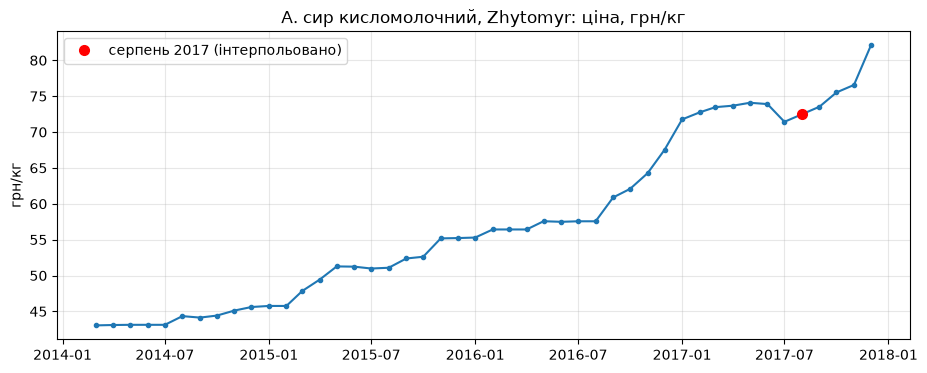

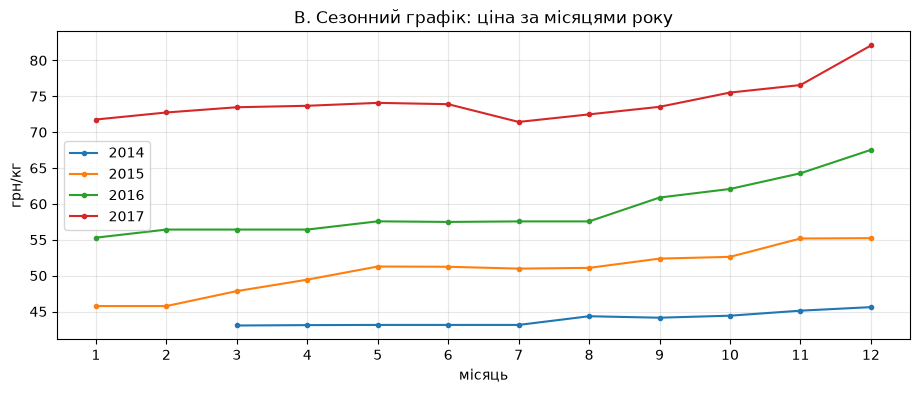

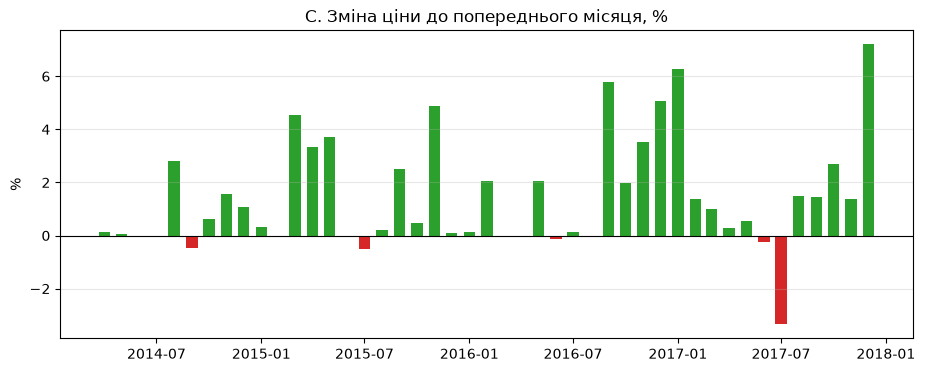

найбільші місячні зростання, %:
date
2017-12-01    7.2
2017-01-01    6.3
2016-09-01    5.8
найбільші місячні падіння, %:
date
2017-07-01   -3.3
2015-07-01   -0.5
2014-09-01   -0.5
ціна: 03.2014 = 43.05, 12.2017 = 82.08 (x1.91)


In [5]:
# Завдання 3. Візуальна розвідка
import matplotlib.pyplot as plt

# A. Лінія ціни в часі: як ціна змінювалась загалом
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(y.index, y.values, marker='o', ms=3)
ax.plot(gap, y[gap], 'o', color='red', ms=7, label='серпень 2017 (інтерпольовано)')
ax.set_title(f'A. {GOOD_UA}, {MARKET}: ціна, грн/кг')
ax.set_ylabel('грн/кг'); ax.grid(alpha=.3); ax.legend()
plt.show()

# B. Сезонний графік: кожен рік окремою лінією, по осі X — місяць
fig, ax = plt.subplots(figsize=(11, 4))
for year, part in y.groupby(y.index.year):
    ax.plot(part.index.month, part.values, marker='o', ms=3, label=str(year))
ax.set_xticks(range(1, 13))
ax.set_title('B. Сезонний графік: ціна за місяцями року')
ax.set_xlabel('місяць'); ax.set_ylabel('грн/кг'); ax.grid(alpha=.3); ax.legend()
plt.show()

# C. Місячна зміна ціни, %: наскільки великі зміни і чи є аномальні стрибки
change = y.pct_change().dropna() * 100
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(change.index, change.values, width=20,
       color=['tab:green' if v >= 0 else 'tab:red' for v in change.values])
ax.axhline(0, color='black', lw=.8)
ax.set_title('C. Зміна ціни до попереднього місяця, %')
ax.set_ylabel('%'); ax.grid(alpha=.3, axis='y')
plt.show()

print('найбільші місячні зростання, %:'); print(change.nlargest(3).round(1).to_string())
print('найбільші місячні падіння, %:');   print(change.nsmallest(3).round(1).to_string())
print('ціна: 03.2014 = %.2f, 12.2017 = %.2f (x%.2f)' % (y.iloc[0], y.iloc[-1], y.iloc[-1] / y.iloc[0]))


**Висновок до завдання 3:**

1. Питання, геометрія і шкала кожного графіка:
   * **A. Лінія ціни в часі** — *як ціна змінювалась загалом?* Лінія, бо точки впорядковані в часі й сусідні місяці пов'язані; точки-маркери показують, що вимір щомісячний, а червона точка — інтерпольований серпень 2017. Шкала лінійна і не з нуля: питання про форму руху (тренд, стрибки), а не про частку від нуля, тому вісь Y підібрана під діапазон 43–82 грн/кг. Видно: за 46 місяців ціна зросла з 43.05 до 82.08 грн/кг (×1.91), і росте вона **сходинками** — плато по кілька місяців, потім різкий стрибок.
   * **B. Сезонний графік** — *чи повторюється щороку однаковий малюнок?* По осі X місяць року, кожен рік окремою лінією: так однакові місяці різних років стоять один над одним і сезонний малюнок, якщо він є, проявився б як однакова форма ліній. Шкала та сама, що й у A. Видно: лінії років не перетинаються — різниця між роками (тренд) значно більша за коливання всередині року. Є лише слабкий натяк на просідання влітку і зростання восени–взимку, але він не повторюється чітко, тож явної сезонності графік не показує (перевіримо числом $F_S$ у завданні 4).
   * **C. Стовпці місячної зміни, %** — *наскільки великі зміни з місяця в місяць, чи є аномальні стрибки?* Стовпці, бо кожна зміна — окрема величина відносно нуля; вісь проходить через 0, колір розділяє зростання й падіння. Відсотки замість гривень, бо ціна подвоїлась і однаковий стрибок у гривнях у 2014 і 2017 роках означав би різну відносну зміну. Видно: ціна майже ніколи не падає; найбільші зростання — 12.2017 (+7.2 %), 01.2017 (+6.3 %), 09.2016 (+5.8 %).
2. **Неочікувана знахідка:** єдине помітне падіння ціни за весь ряд — **липень 2017, −3.3 %** (наступні за величиною падіння лише −0.5 %). Це не загальноукраїнський рух: по 26 ринках сиру в липні 2017 медіанна зміна +0.2 %, падіння було на 11 ринках, тоді як у липні 2015 і 2016 — на 7 і 6. Тобто в липні 2017 літнє здешевлення трапилось частіше, ніж зазвичай, але в Житомирі воно значно глибше. Причину з даних встановити не можна; можливі пояснення — локальне літнє надлишкове пропонування молока або нетиповий вимір (липень стоїть безпосередньо перед місяцем, запис за який у джерелі зник).


## Завдання 4. Розкладання на складові

Розкладіть ряд на тренд, сезонну складову та залишок методом STL із періодом 12.

**У звіті наведіть:**
1. чотирипанельний графік розкладання;
2. числові значення сили сезонності $F_S$ та сили тренду $F_T$;
3. **висновок: чи є у вашому ряді сезонність**, із посиланням на порогове значення.

> 💡 **Підказка.** STL поверне сезонну складову завжди. Ваше завдання — вирішити, чи вона означає щось, а не чи вона є.

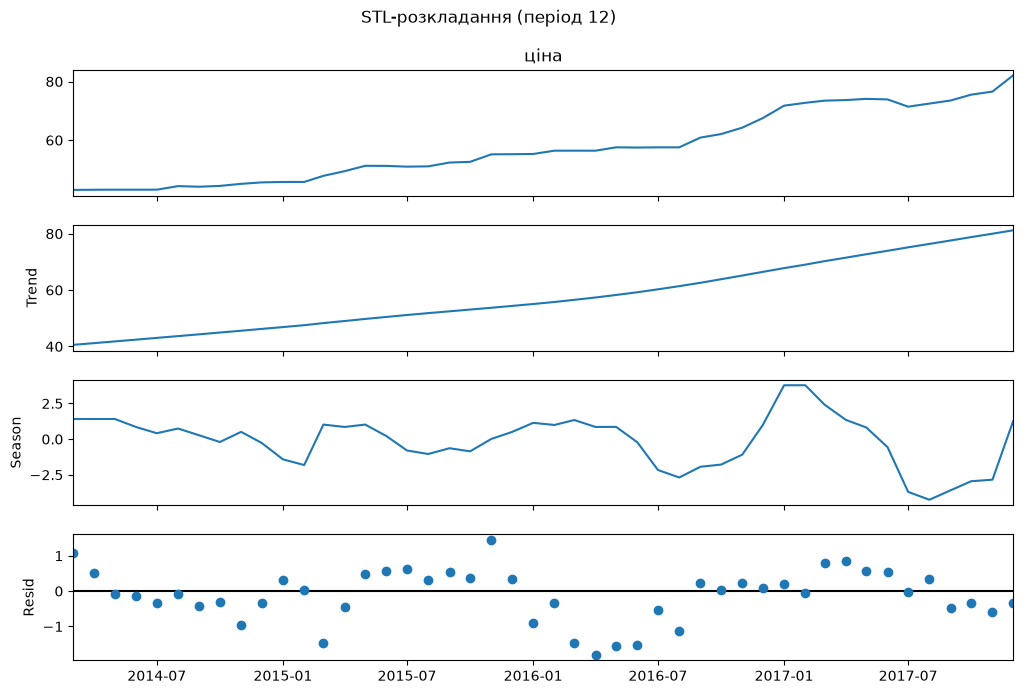

сила сезонності F_S = 0.861   (поріг 0.3)
сила тренду     F_T = 0.996
розмах сезонної складової: від -4.25 до 3.78 грн


In [6]:
# Завдання 4. Розкладання на складові
from statsmodels.tsa.seasonal import STL

stl = STL(y, period=12).fit()
fig = stl.plot()
fig.set_size_inches(11, 7)
fig.suptitle('STL-розкладання (період 12)', y=1.01)
plt.show()

T, S, R = stl.trend, stl.seasonal, stl.resid
F_S = max(0.0, 1 - R.var() / (S + R).var())
F_T = max(0.0, 1 - R.var() / (T + R).var())
print('сила сезонності F_S = %.3f   (поріг 0.3)' % F_S)
print('сила тренду     F_T = %.3f' % F_T)
print('розмах сезонної складової: від %.2f до %.2f грн' % (S.min(), S.max()))


**Висновок до завдання 4:**

1. Чотирипанельний графік STL (період 12) — вище: ряд, тренд (плавно від ≈41 до ≈81 грн), сезонна складова (від −4.25 до +3.78 грн) і залишок (≈ ±1–1.5 грн).
2. Сила сезонності $F_S = 0.861$, сила тренду $F_T = 0.996$. Перевірено, що це не артефакт налаштувань: при жорсткішому сезонному шаблоні (`seasonal=101`) і гнучкішому тренді (`trend=13`) $F_S$ лишається в межах 0.83–0.93.
3. **Формально сезонність є**: $F_S = 0.86$ значно перевищує поріг 0.3. Проте на графіках завдання 3 її майже не видно, і це не суперечність: око порівнювало сезонні коливання (±4 грн) з трендом, що додав майже 40 грн, а $F_S$ тренд прибирає і порівнює сезонну складову лише із залишком (±1 грн) — на тлі такого малого шуму навіть ±4 грн є сильним сигналом. До того ж шаблон нестабільний: у 2014–2015 роках сезонна складова ±1–2 грн, а у 2016–2017 — від +3.8 (зима) до −4.3 (липень 2017), тобто значну частину «сезонності» дають саме стрибки останніх двох років, а не однаковий щорічний малюнок; на 46 місяцях кожен місяць року має лише 3–4 повтори. Висновок: сезонність статистично виражена, але мала порівняно з трендом і нестійка; чи має вона практичну цінність, покаже порівняння сезонного наївного прогнозу зі звичайним у завданні 6.


## Завдання 5. Стаціонарність

Побудуйте ACF і PACF вихідного ряду та його першої різниці. Застосуйте тести ADF і KPSS до обох.

**У звіті наведіть:**
1. графіки ACF і PACF до та після диференціювання;
2. таблицю з $p$-значеннями обох тестів для обох рядів;
3. висновок про стаціонарність **із зазначенням, узгоджуються тести між собою чи ні**;
4. якщо не узгоджуються — ваше пояснення, чому.

> 💡 **Підказка.** Нульові гіпотези ADF і KPSS протилежні. Перш ніж писати висновок, перевірте, що ви не переплутали напрямок.

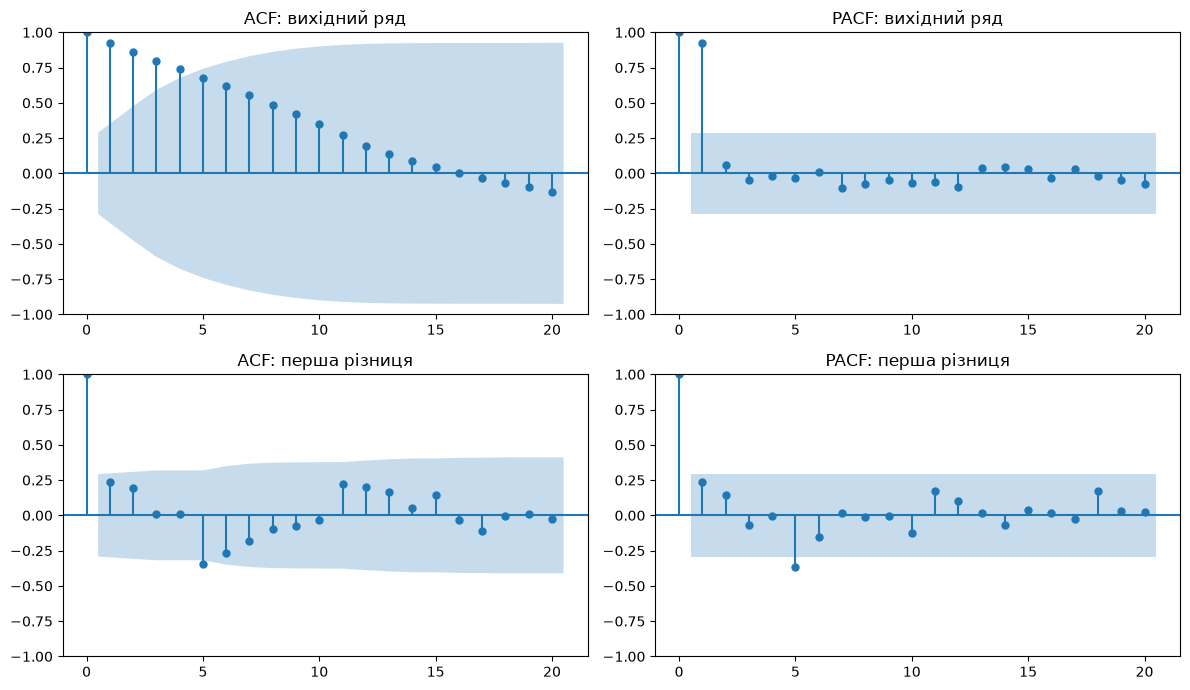

,ADF p (H0: нестаціонарний),KPSS p (H0: стаціонарний)
ряд,,
вихідний ряд,1.0000,0.01
перша різниця,0.0076,0.10


In [7]:
# Завдання 5. Стаціонарність
import warnings
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss

dy = y.diff().dropna()   # перша різниця: зміна ціни за місяць, грн

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
plot_acf(y,  lags=20, ax=axes[0, 0], title='ACF: вихідний ряд')
plot_pacf(y, lags=20, ax=axes[0, 1], title='PACF: вихідний ряд', method='ywm')
plot_acf(dy,  lags=20, ax=axes[1, 0], title='ACF: перша різниця')
plot_pacf(dy, lags=20, ax=axes[1, 1], title='PACF: перша різниця', method='ywm')
plt.tight_layout(); plt.show()

rows = []
for name, s in [('вихідний ряд', y), ('перша різниця', dy)]:
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')          # KPSS попереджає, коли p за межами таблиці
        p_kpss = kpss(s, regression='c', nlags='auto')[1]
    rows.append({'ряд': name,
                 'ADF p (H0: нестаціонарний)': round(adfuller(s, autolag='AIC', result_object=False)[1], 4),
                 'KPSS p (H0: стаціонарний)':  round(p_kpss, 4)})
tests = pd.DataFrame(rows).set_index('ряд')
display(tests)


**Висновок до завдання 5:**

1. Графіки ACF і PACF до та після диференціювання — вище. У вихідного ряду ACF спадає дуже повільно (0.92, 0.86, 0.80, …), а PACF має один великий стовпчик на лагу 1 — типова картина ряду з трендом: кожне значення майже дорівнює попередньому. У першої різниці майже всі лаги в межах значущості; виходить лише лаг 5 (≈ −0.35 в ACF і PACF); на лагу 12 значущої автокореляції немає.
2. $p$-значення (KPSS повертає $p$ лише в межах таблиці 0.01–0.10, тож 0.01 означає «≤ 0.01», а 0.10 — «≥ 0.10»):

| ряд | ADF $p$ (H₀: нестаціонарний) | KPSS $p$ (H₀: стаціонарний) |
|---|---|---|
| вихідний ряд | 1.0000 | 0.01 |
| перша різниця | 0.0076 | 0.10 |

3. **Вихідний ряд нестаціонарний**: ADF не відкидає H₀ про нестаціонарність ($p = 1.0$), а KPSS відкидає H₀ про стаціонарність ($p ≤ 0.01$). **Перша різниця стаціонарна**: ADF відкидає нестаціонарність ($p = 0.0076 < 0.05$), KPSS не відкидає стаціонарність ($p ≥ 0.10$). Тести узгоджуються між собою для обох рядів: сама ціна дрейфує вгору, а її місячні зміни коливаються навколо сталого рівня. Отже, достатньо одного диференціювання, що відповідає $d = 1$ в ARIMA.
4. Суперечності між тестами немає, тож пояснення розбіжності не потрібне.


## Завдання 6. Базисні прогнози та ретроспективна перевірка

Побудуйте **чотири** базисні прогнози: наївний, сезонний наївний, середнє та дрейф.
Оцініть їх **ретроспективною перевіркою з рухомим початком**: **7 фолдів по 3 кроки**,
навчальна частина розширюється.

**У звіті наведіть:**
1. таблицю MAE, RMSE і MAPE для всіх чотирьох базисів;
2. який базис виявився найкращим і **чому саме він** — поясніть через властивості вашого ряду;
3. для порівняння: ту саму оцінку, зроблену звичайним випадковим поділом 75/25, і **у скільки разів** вона відрізняється.

> 💡 **Підказка.** Кількість фолдів і кроків задана жорстко — у Частині 2 вона має збігтися з налаштуваннями Orange.

In [8]:
# Завдання 6. Базисні прогнози та ретроспективна перевірка
import numpy as np

H, FOLDS = 3, 7

def naive(train, h):          # завтра як сьогодні
    return np.repeat(train.iloc[-1], h)

def seasonal_naive(train, h): # як рік тому
    return train.iloc[-12:].values[:h]

def mean_fc(train, h):        # середнє всієї навчальної частини
    return np.repeat(train.mean(), h)

def drift(train, h):          # продовжити пряму від першої до останньої точки
    slope = (train.iloc[-1] - train.iloc[0]) / (len(train) - 1)
    return train.iloc[-1] + slope * np.arange(1, h + 1)

BASELINES = {'наївний': naive, 'сезонний наївний': seasonal_naive,
             'середнє': mean_fc, 'дрейф': drift}

def metrics(actual, pred):
    e = np.asarray(actual) - np.asarray(pred)
    return {'MAE': np.mean(np.abs(e)),
            'RMSE': np.sqrt(np.mean(e ** 2)),
            'MAPE, %': np.mean(np.abs(e / np.asarray(actual))) * 100}

def rolling_origin(forecast, series=y):
    """7 фолдів по 3 кроки, відлік від кінця: фолд f вчиться на всьому до позиції −3f."""
    actual, pred = [], []
    for f in range(1, FOLDS + 1):
        end = len(series) - H * f
        train, test = series.iloc[:end], series.iloc[end:end + H]
        actual += list(test.values); pred += list(forecast(train, H))
    return metrics(actual, pred)

rolling = pd.DataFrame({name: rolling_origin(fc) for name, fc in BASELINES.items()}).T.round(3)
print('Рухомий початок: 7 фолдів × 3 кроки (перевіряються останні 21 місяць)')
display(rolling)

# Для порівняння — випадковий поділ 75/25: тестові місяці розкидані по всьому ряду,
# тож прогноз спирається і на минуле, і на майбутнє відносно тестової точки.
rng = np.random.default_rng(13)
test_idx = np.sort(rng.choice(len(y), size=round(len(y) * 0.25), replace=False))
train_mask = np.ones(len(y), bool); train_mask[test_idx] = False
tr = y[train_mask]

def random_split_pred(name, t):
    before = y.iloc[:t][train_mask[:t]]                      # відомі точки до t
    if name == 'наївний':
        return before.iloc[-1] if len(before) else tr.iloc[0]
    if name == 'сезонний наївний':
        k = t - 12
        while k >= 0 and not train_mask[k]: k -= 12
        return y.iloc[k] if k >= 0 else (before.iloc[-1] if len(before) else tr.iloc[0])
    if name == 'середнє':
        return tr.mean()                                     # середнє включає майбутні місяці
    if name == 'дрейф':                                      # нахил за весь train, від останньої відомої точки
        pos = np.flatnonzero(train_mask)
        slope = (tr.iloc[-1] - tr.iloc[0]) / (pos[-1] - pos[0])
        last = pos[pos < t]
        return (y.iloc[last[-1]] + slope * (t - last[-1])) if len(last) else tr.iloc[0]

random75 = pd.DataFrame({name: metrics(y.iloc[test_idx], [random_split_pred(name, t) for t in test_idx])
                         for name in BASELINES}).T.round(3)
print('Випадковий поділ 75/25 (%d тестових місяців)' % len(test_idx))
display(random75)
print('У скільки разів MAE на рухомому початку більша за MAE випадкового поділу:')
print((rolling['MAE'] / random75['MAE']).round(2).to_string())


Рухомий початок: 7 фолдів × 3 кроки (перевіряються останні 21 місяць)


,MAE,RMSE,"MAPE, %"
наївний,2.449,3.426,3.451
сезонний наївний,12.080,12.714,17.321
середнє,16.105,16.994,22.999
дрейф,2.147,2.687,3.015


Випадковий поділ 75/25 (12 тестових місяців)


,MAE,RMSE,"MAPE, %"
наївний,1.805,2.752,2.754
сезонний наївний,10.089,13.021,14.136
середнє,13.219,14.143,21.881
дрейф,1.475,1.839,2.476


У скільки разів MAE на рухомому початку більша за MAE випадкового поділу:
наївний             1.36
сезонний наївний    1.20
середнє             1.22
дрейф               1.46


**Висновок до завдання 6:**

1. Таблиці MAE, RMSE і MAPE для чотирьох базисів — вище (рухомий початок: 7 фолдів × 3 кроки, перевіряються останні 21 місяць).
2. **Найкращий базис — дрейф** (MAE 2.15 грн, MAPE 3.0 %), трохи гірший наївний (MAE 2.45 грн). Це пояснюється головною властивістю ряду — сильним висхідним трендом: за 46 місяців ціна зросла з 43.05 до 82.08 грн (у середньому ≈ +0.87 грн/міс). Дрейф продовжує саме цей ріст. Наївний прогноз близький до нього, бо ціна росте сходинками з плато і на 3 місяці вперед «як зараз» часто влучає, але на підйомах систематично недооцінює. **Середнє** найгірше (MAE 16.1 грн): воно усереднює й ціни 2014 року (≈43 грн), які далеко нижчі за поточні 70–80 грн. **Сезонний наївний** (MAE 12.1 грн) програє в 5–6 разів: «як рік тому» означає ціну, нижчу через тренд на 10–15 грн, а сезонні коливання (±4 грн, завдання 4) значно менші за річний приріст. Отже, сезонність, яку формально показав $F_S = 0.86$, практичної цінності для прогнозу не має.
3. При випадковому поділі 75/25 (12 тестових місяців) MAE менша: наївний 1.81, дрейф 1.48, сезонний наївний 10.09, середнє 13.22 грн — тобто рухомий початок дає помилку в **1.2–1.5 раза більшу** (наївний ×1.36, дрейф ×1.46). Випадковий поділ прикрашає результат, бо тестові місяці розкидані по всьому ряду і прогноз спирається на сусідні, зокрема пізніші, виміри — «підглядає в майбутнє». Для прогнозування чесна лише оцінка з рухомим початком.


## Завдання 7. Модель ARIMA

Побудуйте модель ARIMA і оцініть її **на тих самих 7 фолдах по 3 кроки**.

Обов'язково використайте порядок **(1, 1, 1)** — саме його ви відтворюватимете в Orange.
Додатково визначте, який порядок $(p, d, q)$ ви обрали б **за виглядом ACF і PACF** із завдання 5.

**У звіті наведіть:**
1. MAE, RMSE і MAPE моделі ARIMA(1,1,1) на рухомому початку;
2. обґрунтування порядку, який ви обрали б самостійно, з посиланням на конкретні лаги;
3. **порівняння з найкращим базисом із завдання 6** — і прямий висновок, чи має ця модель право на існування;
4. графік залишків моделі та висновок, чи лишилася в них структура.

> 💡 **Підказка.** Якщо ARIMA програла базису — це законний результат, а не помилка. Напишіть про це прямо.

,MAE,RMSE,"MAPE, %"
"ARIMA(1,1,1)",1.919,2.567,2.687
"ARIMA(0,1,0) з ACF/PACF різниці",2.449,3.426,3.451
дрейф (найкращий базис),2.147,2.687,3.015


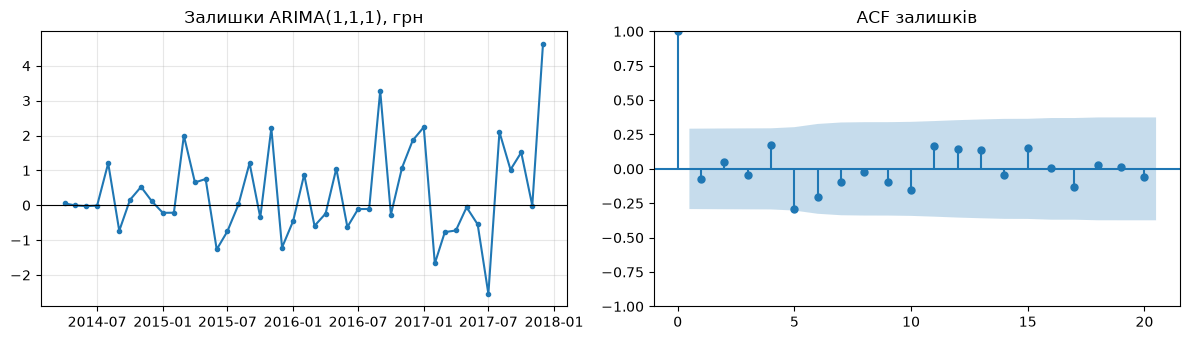

Ljung-Box (H0: у залишках немає автокореляції), p для лагів 6 і 12:
6     0.187
12    0.285


In [9]:
# Завдання 7. Модель ARIMA
from statsmodels.tsa.arima.model import ARIMA

def arima_fc(order):
    def fc(train, h):
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            return ARIMA(train.reset_index(drop=True), order=order).fit().forecast(h).values
    return fc

arima_rows = {'ARIMA(1,1,1)': rolling_origin(arima_fc((1, 1, 1))),
              'ARIMA(0,1,0) з ACF/PACF різниці': rolling_origin(arima_fc((0, 1, 0))),
              'дрейф (найкращий базис)': rolling.loc['дрейф'].to_dict()}
display(pd.DataFrame(arima_rows).T.round(3))

with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    full = ARIMA(y.reset_index(drop=True), order=(1, 1, 1)).fit()
resid = pd.Series(full.resid.values[1:], index=y.index[1:])   # перший залишок = сама ціна, відкидаємо

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(resid.index, resid.values, marker='o', ms=3); axes[0].axhline(0, color='black', lw=.8)
axes[0].set_title('Залишки ARIMA(1,1,1), грн'); axes[0].grid(alpha=.3)
plot_acf(resid, lags=20, ax=axes[1], title='ACF залишків')
plt.tight_layout(); plt.show()

from statsmodels.stats.diagnostic import acorr_ljungbox
print('Ljung-Box (H0: у залишках немає автокореляції), p для лагів 6 і 12:')
print(acorr_ljungbox(resid, lags=[6, 12])['lb_pvalue'].round(3).to_string())


**Висновок до завдання 7:**

1. ARIMA(1,1,1) на тих самих 7 фолдах × 3 кроки: **MAE 1.92 грн, RMSE 2.57 грн, MAPE 2.69 %**.
2. Власний вибір порядку за ACF/PACF із завдання 5: $d = 1$ (одна різниця робить ряд стаціонарним); у першої різниці ACF і PACF на лагах 1–4 та 12 у межах значущості, виходить лише лаг 5 (≈ −0.35), який на 46 точках можна вважати випадковим. Тому сам я обрав би **ARIMA(0,1,0)** — випадкове блукання, тобто наївний прогноз; на рухомому початку вона дає MAE 2.45 грн, рівно як наївний базис.
3. Порівняння з найкращим базисом — дрейфом (MAE 2.15, RMSE 2.69, MAPE 3.02 %): ARIMA(1,1,1) краща за всіма трьома метриками, MAE менша на ≈ 11 %. Модель має право на існування, але перевага невелика — простий дрейф відстає ненабагато.
4. Залишки моделі (графік вище) коливаються навколо нуля без тренду; в ACF залишків значущих лагів немає, тест Ljung–Box не відкидає відсутність автокореляції ($p = 0.19$ для 6 лагів, $p = 0.29$ для 12). Помітної структури в залишках не лишилося.


## Завдання 8. Точка зміни режиму

Знайдіть у своєму ряді точку, після якої змінюється **рівень** ряду.
Скористайтеся скануванням: для кожної кандидатної дати порівняйте середні до і після
та оберіть дату з найбільшою t-статистикою.

**У звіті наведіть:**
1. графік ряду з позначеною знайденою датою;
2. дату, значення t-статистики, середні рівні до і після;
3. **чи є ця точка значущою** — і якщо ні, так і напишіть;
4. чим знайдена точка відрізняється від звичайного сезонного сплеску у вашому ряді.

> 💡 **Підказка.** Не плутайте зсув рівня з сезонним піком. Якщо «аномалії» повторюються щороку в ті самі місяці — це сезон.

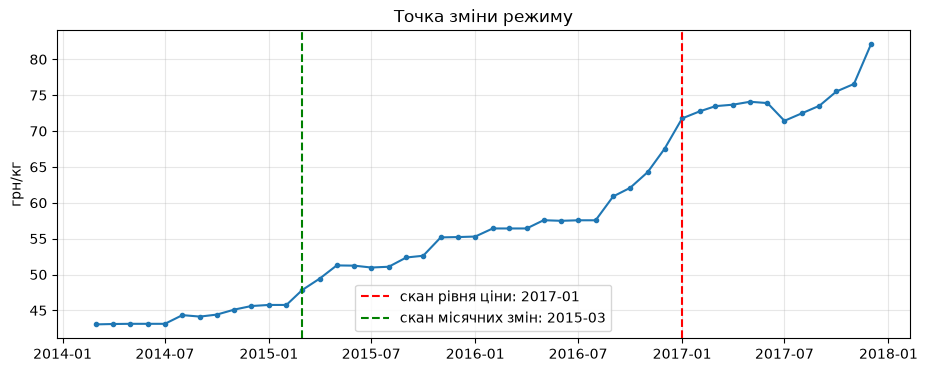

Скан рівня ціни : 2017-01, t = 15.74, p = 2.3e-19, середнє до 51.69, після 74.27 грн
Скан місячних змін: 2015-03, t = 2.89, p = 0.006, середня зміна до 0.25, після 1.07 грн/міс


In [10]:
# Завдання 8. Точка зміни режиму
from scipy import stats

cands = []
for k in range(6, len(y) - 6):            # мінімум 6 місяців з кожного боку
    before, after = y.iloc[:k], y.iloc[k:]
    t, p = stats.ttest_ind(after, before, equal_var=False)
    cands.append((y.index[k], t, p, before.mean(), after.mean()))
cp = pd.DataFrame(cands, columns=['дата', 't', 'p', 'середнє до', 'середнє після']).set_index('дата')
best = cp['t'].abs().idxmax()

# Самі рівні ціни мають тренд, тож t-тест на них «знайде» зсув будь-де.
# Тому повторюємо скан на місячних змінах ціни (стаціонарний ряд): зсув рівня швидкості зростання.
cands_d = []
for k in range(6, len(dy) - 6):
    before, after = dy.iloc[:k], dy.iloc[k:]
    t, p = stats.ttest_ind(after, before, equal_var=False)
    cands_d.append((dy.index[k], t, p, before.mean(), after.mean()))
cpd = pd.DataFrame(cands_d, columns=['дата', 't', 'p', 'середнє до', 'середнє після']).set_index('дата')
best_d = cpd['t'].abs().idxmax()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(y.index, y.values, marker='o', ms=3)
ax.axvline(best, color='red', ls='--', label='скан рівня ціни: %s' % best.strftime('%Y-%m'))
ax.axvline(best_d, color='green', ls='--', label='скан місячних змін: %s' % best_d.strftime('%Y-%m'))
ax.set_title('Точка зміни режиму'); ax.set_ylabel('грн/кг'); ax.grid(alpha=.3); ax.legend()
plt.show()

print('Скан рівня ціни : %s, t = %.2f, p = %.2g, середнє до %.2f, після %.2f грн'
      % (best.strftime('%Y-%m'), *cp.loc[best, ['t', 'p', 'середнє до', 'середнє після']]))
print('Скан місячних змін: %s, t = %.2f, p = %.3f, середня зміна до %.2f, після %.2f грн/міс'
      % (best_d.strftime('%Y-%m'), *cpd.loc[best_d, ['t', 'p', 'середнє до', 'середнє після']]))


**Висновок до завдання 8:**

1. Графік ряду з позначеними датами — вище.
2. Скан рівня ціни (t-тест середніх до/після для кожної дати, щонайменше 6 місяців з кожного боку): максимум |t| у **січні 2017**, $t = 15.7$, середнє до 51.69 грн, після 74.27 грн. Проте ряд має тренд, тож середнє «після» більше за «до» майже для будь-якої дати; тому скан повторено на місячних змінах ціни (стаціонарному ряді): зсув у **березні 2015**, $t = 2.89$, $p = 0.006$ — середня зміна до 0.25 грн/міс, після 1.07 грн/міс.
3. Для рівня ціни $p ≈ 10^{-19}$ формально значуще, але це наслідок тренду, а не окремого зсуву, тому самостійним доказом зміни режиму не є. Зсув у березні 2015 значущий ($p = 0.006 < 0.05$): до весни 2015 ціна майже стояла, після — росте в середньому на ≈ 1 грн/міс. Зовнішнє пояснення правдоподібне — девальвація гривні на початку 2015 року, але з цих даних воно не доводиться.
4. Сезонний сплеск повторювався б щороку в ті самі місяці й потім повертався назад; знайдена точка — разова й незворотна зміна швидкості зростання, після якої ціна вже не повертається до попереднього темпу.


## Завдання 9. Рецензія на чужий аналіз

Відкрийте `ЛР4_помилковий_аналіз.ipynb`. Це звіт, зроблений на іншому ряді з того самого набору.
Він виконується без помилок і виглядає переконливо, але містить **методологічні помилки**.

**У звіті наведіть:**
1. перелік знайдених помилок — для кожної вкажіть номер клітинки, суть помилки й **чим вона небезпечна**;
2. для трьох найсерйозніших — як саме їх виправити.

> 💡 **Підказка.** Помилок щонайменше вісім. Шукайте не синтаксис, а порушення принципів роботи з часовими рядами.

In [11]:
# Завдання 9. Рецензія на чужий аналіз
# Перевіряємо числами кілька помилок колеги на ЙОГО ряді (гречка, Вінниця)
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.arima.model import ARIMA

d9 = pd.read_csv('ціни_україна_2014_2017.csv')
d9['date'] = pd.to_datetime(dict(year=d9['рік'], month=d9['місяць'], day=1))
def get9(market, good):
    x = d9[(d9['ринок'] == market) & (d9['товар'] == good)]
    return x.set_index('date')['ціна'].sort_index()

buck = get9('Vinnytsia', 'Buckwheat grits - Retail')    # ряд колеги як є
grid9 = pd.date_range('2014-03-01', '2017-12-01', freq='MS')
bg = buck.reindex(grid9).interpolate()                  # як треба: повна сітка, пропуск заповнено

# 1) клітинка 3: «пропусків немає»
print('1) рядків у колеги:', len(buck), '| місяців у сітці:', len(grid9),
      '| немає місяця:', [d.strftime('%m.%Y') for d in grid9.difference(buck.index)])

# 2) клітинка 11: сила сезонності F_S; клітинка 15: аномалії в залишках STL
for name, x, rob in [('як у колеги (45 точок, robust)', buck, True), ('повна сітка, звичайний STL', bg, False)]:
    st = STL(x, period=12, robust=rob).fit()
    FS = max(0, 1 - st.resid.var() / (st.seasonal + st.resid).var())
    z = (st.resid - st.resid.mean()) / st.resid.std()
    print('2) %-31s F_S = %.2f (поріг 0.3) | аномалії в залишках (|z|>2): %s'
          % (name, FS, ', '.join(d.strftime('%m.%Y') for d in z[z.abs() > 2].index)))

# 3) клітинка 13: ADF і KPSS для рівня та першої різниці
for name, x in [('рівень', bg), ('1-а різниця', bg.diff().dropna())]:
    print('3) %-11s ADF p = %.3f | KPSS p = %.3f' % (name, adfuller(x)[1], kpss(x, nlags='auto')[1]))
print('   розкид: 1-а різниця std = %.2f, 2-а різниця std = %.2f' % (bg.diff().std(), bg.diff().diff().std()))

# 4) клітинка 7: помилка наївного прогнозу у грн (MAE) і у відсотках (MAPE)
beef9 = get9('Vinnytsia', 'Meat (beef) - Retail').reindex(grid9).interpolate()
for name, x in [('гречка', bg), ('яловичина', beef9)]:
    e = (x - x.shift(1)).dropna().abs()
    print('4) %-9s середня ціна %.1f грн | MAE = %.2f грн | MAPE = %.1f %%'
          % (name, x.mean(), e.mean(), (e / x[e.index]).mean() * 100))

# 5) клітинка 17: чесна перевірка — рухомий початок, 7 фолдів по 3 кроки від кінця
n = len(bg); ea, en, fact = [], [], []
for f in range(7, 0, -1):
    tr, te = bg.iloc[:n - 3*f], bg.iloc[n - 3*f : n - 3*f + 3]
    ea += list(np.abs(te.values - ARIMA(tr.values, order=(1, 1, 1)).fit().forecast(3)))
    en += list(np.abs(te.values - tr.iloc[-1]))              # наївний: «як в останньому місяці»
    fact += list(te.values)
ea, en, fact = map(np.array, (ea, en, fact))
print('5) ARIMA(1,1,1): MAE = %.2f грн, MAPE = %.1f %%' % (ea.mean(), (ea / fact).mean() * 100))
print('   наївний      : MAE = %.2f грн, MAPE = %.1f %%' % (en.mean(), (en / fact).mean() * 100))


1) рядків у колеги: 45 | місяців у сітці: 46 | немає місяця: ['08.2017']
2) як у колеги (45 точок, robust)  F_S = 0.16 (поріг 0.3) | аномалії в залишках (|z|>2): 06.2016, 07.2016, 08.2016
2) повна сітка, звичайний STL      F_S = 0.61 (поріг 0.3) | аномалії в залишках (|z|>2): 06.2016, 07.2016, 08.2016
3) рівень      ADF p = 0.348 | KPSS p = 0.018
3) 1-а різниця ADF p = 0.040 | KPSS p = 0.065
   розкид: 1-а різниця std = 2.05, 2-а різниця std = 2.22
4) гречка    середня ціна 21.4 грн | MAE = 1.35 грн | MAPE = 6.1 %
4) яловичина середня ціна 79.0 грн | MAE = 1.47 грн | MAPE = 1.9 %
5) ARIMA(1,1,1): MAE = 2.77 грн, MAPE = 10.8 %
   наївний      : MAE = 2.55 грн, MAPE = 10.1 %


**Висновок до завдання 9:**

Звіт колеги (гречка, Вінниця) я перевірив повністю: усі 23 клітинки, код, текст і вивід. Знайшов **10 методологічних помилок**. Номер клітинки — індекс з 0; у дужках — мітка `In [n]` і розділ звіту. Числа з позначкою «код 1)…5)» дає моя клітинка вище.

1. **Клітинка 3** (`In [2]`, розділ «1. Підготовка даних»; ряд зібрано в клітинці 1). Колега пише, що пропусків немає. Насправді в ряді 45 місяців замість 46: серпня 2017 немає взагалі (код 1). `isna()` його не бачить, бо рядка просто немає, а не стоїть NaN. Сітку `grid` колега створив, але не використав.
   *Чим небезпечно:* усі методи рахують кроки за рядками. Тому вересень 2017 стає «наступним місяцем» після липня. `shift(1)`, `shift(12)`, STL з періодом 12 і ARIMA після пропуску зсуваються на місяць.

2. **Клітинка 5** (`In [3]`, «2. Динаміка цін»). Висновок «подорожчала у 2.5 раза» зроблено лише за двома точками: березень 2014 і грудень 2017. Але в липні 2016 ціна була 36.93 грн, тобто в 5.2 раза більша за початкову, а потім упала вдвічі. Крім того, «зниження купівельної спроможності» з цих даних не випливає: це номінальні ціни, а даних про інфляцію й доходи немає.
   *Чим небезпечно:* з іншою парою місяців вийде будь-яке потрібне число. Висновок про добробут ні на чому не ґрунтується.

3. **Клітинка 7** (`In [4]`, «3. Порівняння з іншим товаром»). Колега порівнює MAE в гривнях для товарів з різним рівнем ціни: гречка в середньому коштує близько 21 грн, яловичина близько 79 грн. Похибка у відсотках дає протилежний результат: MAPE для гречки 6.1 %, для яловичини 1.9 % (код 4). Отже, яловичину прогнозувати втричі легше, а не важче. До того ж питання розділу («чи подорожчання виняткове?») точність прогнозу взагалі не розв'язує.
   *Чим небезпечно:* MAE залежить від масштабу ряду. Порівнювати різні ряди за MAE — те саме, що порівнювати помилку в копійках і в гривнях. Висновок вийшов навпаки.

4. **Клітинка 9** (`In [5]`, «4. Зростання цін у двох областях»). З кореляції r = 0.996 колега робить висновок, що «ціни у Львові визначають ціни у Вінниці». Кореляція не показує, що чим керує. Обидва ряди мають спільний тренд, а будь-які два ряди, що ростуть, дають високе r, навіть якщо вони не пов'язані. Тут ряди справді рухаються разом, але найімовірніше через спільну причину (загальний ринок гречки, девальвація), а не тому, що Львів впливає на Вінницю.
   *Чим небезпечно:* хибний причинно-наслідковий висновок і завищена через тренд кореляція.

5. **Клітинка 11** (`In [6]`, «5. Розкладання ряду на складові»). Колега вважає ряд сезонним лише тому, що STL повернув сезонну складову. Але STL повертає її завжди. Вирішує сила сезонності $F_S$, а на розкладі самого колеги $F_S = 0.16 < 0.3$, тобто сезонної складової фактично немає (код 2). «Амплітуда 10 грн» — це разові стрибки (грудень 2014, літо 2016), а не повтор щороку. До того ж «сезонні моделі» далі так і не використано: ARIMA несезонна.
   *Чим небезпечно:* шум приймають за сезон і обирають не ту модель.

6. **Клітинка 13** (`In [7]`, «6. Перевірка стаціонарності»). Висновок ADF перевернуто. У ADF нульова гіпотеза — «ряд нестаціонарний». p = 0.233 > 0.05, тому її не відхиляємо, і ряд **нестаціонарний**, а не стаціонарний. KPSS не застосовано. Потім колега «для надійності» бере різницю двічі, що суперечить його ж висновку «диференціювання не потрібне». Перевірка показує, що досить однієї різниці (код 3), а друга різниця лише збільшує розкид (2.05 → 2.22). Це ознака зайвого диференціювання.
   *Чим небезпечно:* нестаціонарний ряд моделюють як стаціонарний. Або, як тут, беруть d = 2, і модель далі продовжує випадковий нахил (див. помилку 9).

7. **Клітинка 15** (`In [8]`, «7. Пошук аномалій»). Аномалії шукають у вихідному ряді з трендом. У тексті вказано поріг «два стандартні відхилення», а в коді стоїть 1.3. З порогом 2 не знайшлося б жодного місяця. «Аномальними» вийшли 12 з 45 місяців, серед них увесь 2014 рік (9 місяців). Це просто низький рівень до подорожчання, тобто тренд. У залишках STL виділяється лише літо 2016 (06–08.2016, код 2), тобто справжній разовий сплеск.
   *Чим небезпечно:* тренд видають за «нетипові події», а справжня аномалія губиться серед хибних. Поріг підібрано під бажаний результат.

8. **Клітинка 17** (`In [9]`, «8. Побудова та перевірка прогнозної моделі»). Ряд поділено випадково 75/25 (`train_test_split`). У навчання потрапили майбутні місяці, зокрема останній, грудень 2017, а в тест — місяці 2014 року. Навчальні точки склеєно так, ніби вони йдуть підряд. Прогноз зроблено на місяці після 12.2017, а порівняно з відсортованими тестовими цінами з минулого, тобто з іншими місяцями. Сезонний наївний прогноз оцінено на інших точках, тому порівнювати з ним не можна. Звичайний наївний прогноз (MAE 1.38 грн у клітинці 7) у 6 разів кращий за «модель» з MAE 8.73 грн, але це проігноровано. Похибка 8.73 грн при середній ціні 21 грн — це приблизно 40 %, а не «висока точність». MAPE не пораховано.
   *Чим небезпечно:* оцінка якості не має сенсу, бо модель «бачила майбутнє», а тест порівнюють не з тими місяцями. Модель, гірша за наївний прогноз, подається як придатна.

9. **Клітинка 19** (`In [10]`, «9. Прогноз на наступний рік»). Для прогнозу взято іншу модель, ARIMA(2,2,1), а не ту, що перевіряли (1,1,1). Її ніде не перевірено. d = 2 — наслідок помилки 6. Модель навчено на масиві без дат, тобто знову без урахування пропуску. Прогноз на грудень 2018 — 8.95 грн, удвічі менше за останню ціну 17.67 грн, а у висновку написано «ціна продовжить зростати». Немає ні інтервалів прогнозу, ні порівняння з наївним прогнозом.
   *Чим небезпечно:* читач отримує неперевірений прогноз, і текст суперечить власному числу колеги.

10. **Клітинка 21** (`In [11]`, «10. Динаміка за 2016 рік»). На стовпчиковій діаграмі вісь Y обрізано (від min·0.995). Стовпчик січня майже нульовий, а червня у ~80 разів вищий, хоча ціна зросла лише на 41 %. Стовпчики завжди мають починатися з нуля. Розділ називається «за 2016 рік», а показано лише січень–червень. Друге півріччя, коли ціна впала з 36.93 до 27.35 грн, приховано. За весь рік ріст склав близько 10 %.
   *Чим небезпечно:* графік перебільшує зміну, а вибір вікна приховує падіння. Це маніпуляція, навіть якщо ріст у першому півріччі справді був.

Підсумкова клітинка 22 («Загальні висновки») лише повторює помилки 2, 4, 5, 6, 8 і 9, тому окремою помилкою я її не рахую. Але всі шість висновків у ній або хибні, або не доведені.

**Як виправити три найсерйозніші помилки**

1. **Перевірка моделі (клітинка 17).** Випадковий поділ прибрати. Для часового ряду навчання має йти лише на минулому, а тест — на майбутньому. Робимо ретроспективну перевірку з рухомим початком: 7 фолдів по 3 кроки, від кінця ряду. Для фолду $f$ навчаємось на перших $n - 3f$ місяцях і прогнозуємо наступні 3. Так перевіряються останні 21 місяць. На тих самих фолдах рахуємо наївний прогноз («як в останньому місяці»). MAE і MAPE усереднюємо по всіх 21 перевірених місяцях, а не по одному фолду. Результат (код 5): ARIMA(1,1,1) — MAE 2.77 грн, MAPE 10.8 %, наївний — MAE 2.55 грн, MAPE 10.1 %. Отже, ARIMA **гірша** за наївний прогноз, і чесний висновок — «модель не виправдала себе», а не «висока точність».

2. **Стаціонарність (клітинка 13).** Читати ADF правильно: велике p означає, що ряд **нестаціонарний**. Обов'язково додати KPSS, у якого нульова гіпотеза протилежна: мале p означає нестаціонарність. Для рівня ряду ADF p = 0.35, KPSS p = 0.018, тож обидва тести кажуть «нестаціонарний» (код 3). Беремо **одну** різницю: ADF p = 0.040, KPSS p = 0.065, тож обидва кажуть «стаціонарний». Отже, d = 1 і на цьому зупиняємось. Другу різницю не брати, бо розкид від неї росте. Тому для прогнозу брати ARIMA(1,1,1), а не (2,2,1).

3. **Сезонність (клітинка 11).** Спочатку привести ряд до повної сітки з 46 місяців і заповнити серпень 2017 (помилка 1), бо STL відлічує період 12 за рядками. Далі порахувати силу сезонності $F_S = \max(0,\ 1 - \mathrm{Var}(R)/\mathrm{Var}(S+R))$ зі складових STL і порівняти з порогом 0.3. На розкладі колеги $F_S = 0.16$, тож сезонності немає і сезонні моделі не потрібні. Застереження: на повній сітці зі звичайним (не robust) STL виходить $F_S = 0.61$, бо без robust разові стрибки 2014 і 2016 років частково потрапляють у «сезон». Тобто відповідь залежить від налаштувань. Їх треба вказати й обґрунтувати, а висновок робити лише за $F_S$, а не за тим, що STL «щось повернув».


## Завдання 10. Експорт ряду для Orange

Збережіть підготовлений ряд у файл `ряд_для_orange.csv` **рівно у такому вигляді**:

| Стовпець | Тип | Зміст |
|---|---|---|
| `date` | текст у форматі `РРРР-ММ-ДД` | перше число місяця |
| `price` | число | ціна, пропуск уже заповнений |

Один рядок на місяць, 46 рядків плюс заголовок, роздільник — кома, кодування UTF-8.

**У звіті наведіть:**
1. підтвердження, що файл має 46 рядків даних і не містить порожніх значень.

> 💡 **Підказка.** Формат заданий жорстко: Orange має отримати **точно ті самі** дані, що й Python, інакше порівняння в Частині 2 втрачає сенс.

In [12]:
# Завдання 10. Експорт ряду для Orange
out = pd.DataFrame({'date': y.index.strftime('%Y-%m-%d'), 'price': y.values.round(4)})
out.to_csv('ряд_для_orange.csv', index=False, encoding='utf-8')

check = pd.read_csv('ряд_для_orange.csv')
print('рядків даних:', len(check), '| порожніх значень:', int(check.isna().sum().sum()))
print(check.head(3).to_string(index=False)); print('...')
print(check[check['date'] == '2017-08-01'].to_string(index=False, header=False))


рядків даних: 46 | порожніх значень: 0
      date   price
2014-03-01 43.0500
2014-04-01 43.1033
2014-05-01 43.1300
...
2017-08-01 72.4767


**Висновок до завдання 10:**

1. Файл `ряд_для_orange.csv` має **46 рядків даних** плюс заголовок, стовпці `date` (РРРР-ММ-ДД, перше число місяця) і `price`, роздільник — кома, кодування UTF-8, **порожніх значень немає**; серпень 2017 заповнено лінійною інтерполяцією (72.4767).


---
# ЧАСТИНА 2. Той самий аналіз засобами Orange

*Виконується самостійно.*

Потрібен додаток **Timeseries**: у Orange відкрийте *Options → Add-ons…* і встановіть `Orange3-Timeseries`.

**Головна умова цієї частини:** Orange має отримати **ті самі дані** й **ті самі налаштування перевірки**,
що й Python у Частині 1. Тоді будь-яка розбіжність у числах пояснюється **лише означеннями метрик**,
а не різними даними чи різними моделями. Саме це вам і треба довести.

## Завдання 11. Потік опрацювання даних

Побудуйте в Orange потік:

`File` → `As Timeseries` → `Interpolate` → `Line Chart`

У віджеті **File** завантажте свій `ряд_для_orange.csv`; переконайтеся, що `date` розпізнано
як **time**, а `price` — як **numeric**. У віджеті **As Timeseries** оберіть `date` як часову змінну.

**У звіті наведіть:**
1. знімок екрана з побудованим потоком;
2. знімок `Line Chart` із вашим рядом;
3. підтвердження, що графік у Orange збігається з графіком із завдання 3.

> 💡 **Підказка.** Якщо `date` розпізнано як текст, поверніться до завдання 10 і перевірте формат дати.

In [13]:
# Завдання 11. Потік опрацювання даних
# Завдання виконується в Orange (потік — файл потік_orange.ows, дані — ряд_для_orange.csv із завдання 10).
# Знімки екрана (потік і Line Chart) вставлено у висновок нижче.

**Висновок до завдання 11:**

1. Потік (файл `потік_orange.ows`): `File → Form Timeseries → Interpolate → Line Chart`. Віджет, який у методичці названо «As Timeseries», у версії Orange 3.40 + Orange3-Timeseries 0.6.3 називається **Form Timeseries**.

![Потік Orange](screenshots/11_flow.png)

2. У віджеті File `date` розпізнано як час (datetime), `price` — як число. Для `price` задано роль **target**: без цього ARIMA Model і Model Evaluation не знають, що прогнозувати.

![Віджет File](screenshots/11_file.png)

3. Line Chart показує той самий ряд, що й графік A із завдання 3: від 43.05 до 82.08 грн/кг, зростання сходинками, ті самі стрибки взимку 2016/17 і в грудні 2017. Interpolate з лінійною інтерполяцією дає за серпень 2017 те саме значення 72.48, що й Python, тож дані в обох середовищах однакові.

![Line Chart](screenshots/11_line_chart.png)

## Завдання 12. Автокореляція та диференціювання

Додайте до потоку віджети `Correlogram`, `Difference` та `Seasonal Adjustment`.

**У звіті наведіть:**
1. знімок корелограми;
2. зіставлення з ACF із завдання 5: **чи збігаються висновки** про значущі лаги;
3. знімок сезонно скоригованого ряду та порівняння з сезонною складовою STL із завдання 4.

> 💡 **Підказка.** Orange і statsmodels рахують автокореляцію однаково — якщо картина різна, перевірте, чи однакові дані на вході.

In [14]:
# Завдання 12. Автокореляція та диференціювання
# Завдання виконується в Orange: Correlogram (ряд і перша різниця), Difference, Seasonal Adjustment (період 12).
# Знімки екрана вставлено у висновок нижче; для зіставлення — ACF із завдання 5 і STL із завдання 4.

**Висновок до завдання 12:**

1. **Корелограма ряду.** Orange показує лише один стовпчик (лаг 33, −0.44), бо віджет Correlogram малює тільки локальні піки |ACF|, а не всі лаги. ACF ціни спадає плавно (0.92, 0.86, 0.80…, завдання 5), тому піків майже немає. Сама автокореляція та сама, різниця лише в тому, які лаги показано.

![Корелограма ціни](screenshots/12_correlogram_price.png)

2. **Корелограма першої різниці** (Difference → Correlogram): лаг 5 = −0.35 і лаг 11 = 0.22 — так само, як у statsmodels (−0.348 і 0.224). Межа значущості в Orange ширша (±0.34 проти ±0.29 у statsmodels, інша формула інтервалу), тому лаг 5 в Orange лежить на межі, а в Python трохи за нею. **Висновки збігаються:** у першій різниці значущої автокореляції майже немає, сезонного лагу 12 немає.

![Корелограма різниці](screenshots/12_correlogram_diff.png)

3. **Seasonal Adjustment** (адитивне розкладання, період 12). Сезонно скоригований ряд (червона лінія) відрізняється від ціни (синя) лише на 1–3 грн, найбільше влітку: наприклад, серпень 2014 (спостереження 5) після зняття сезону вищий за ціну. Отже, сезонна складова влітку від'ємна — як і в STL із завдання 4, де липень–жовтень у середньому на 1.5–1.8 грн нижчі за тренд. Як і STL, Orange показує, що сезон малий порівняно з трендом.

![Сезонно скоригований ряд](screenshots/12_seasonal_adjustment.png)

4. Особливість Orange: Seasonal Adjustment у Timeseries 0.6.3 падає з помилкою «variable date is not in domain», якщо подати йому ряд із часовою змінною (помилка самого додатка). Тому в потоці він стоїть в окремій гілці `File → Select Columns (без date) → Seasonal Adjustment`; через це на осі X номери спостережень 0–45, а не дати.

## Завдання 13. Модель і оцінювання

Додайте `ARIMA Model` з порядком **(1, 1, 1)** та `Model Evaluation`.

У віджеті **Model Evaluation** встановіть **Number of folds = 7** та **Forecast steps = 3**.

**У звіті наведіть:**
1. знімок таблиці Model Evaluation з усіма метриками;
2. **що станеться, якщо лишити типові налаштування** (20 фолдів × 3 кроки) — наведіть повідомлення, яке видасть Orange, і поясніть, звідки воно береться;
3. які саме 7 фолдів перевіряє Orange — тобто на яких відрізках ряду навчається модель.

> 💡 **Підказка.** Orange відмовиться працювати при типових налаштуваннях. Це не збій, а наслідок довжини вашого ряду — порахуйте, якої саме.

In [15]:
# Завдання 13. Модель і оцінювання
# Orange не встановлено в середовищі цього зошита, тому таблицю віджета Model Evaluation
# (ARIMA(1,1,1), Number of folds = 7, Forecast steps = 3) перенесено сюди як константи.
# Ті самі числа перевірено й без інтерфейсу — функцією orangecontrib.timeseries.model_evaluation
# (Orange 3.40, Orange3-Timeseries 0.6.3) на файлі ряд_для_orange.csv.
ORANGE = pd.DataFrame(
    [[2.566727, 1.611131, 0.028124, 85.0,   0.887615,  65.854,  69.388],
     [6.484121, 0.727406, 0.032129, 48.889, 0.686016, 160.568, 165.988]],
    index=['ARIMA(1,1,1)', 'ARIMA(1,1,1) (in-sample)'],
    columns=['RMSE', 'MAE', 'MAPE', 'POCID', 'R²', 'AIC', 'BIC'])
print('Таблиця Model Evaluation з Orange:')
display(ORANGE)

# Які 7 фолдів перевіряє Orange (functions.py, model_evaluation):
#   for fold in 1..n_folds: train_end = -fold * forecast_steps
#   модель вчиться на interp_data[:train_end] і прогнозує forecast_steps наступних точок
n_obs = len(y)
fold_rows = []
for f in range(1, FOLDS + 1):
    end = n_obs - H * f                     # те саме, що позиція -3f
    fold_rows.append({'фолд': f,
                      'train_end': -H * f,
                      'навчання': f'{y.index[0]:%m.%Y} – {y.index[end - 1]:%m.%Y}',
                      'точок у навчанні': end,
                      'перевірка (прогноз на 3 міс.)': f'{y.index[end]:%m.%Y} – {y.index[end + H - 1]:%m.%Y}'})
display(pd.DataFrame(fold_rows).set_index('фолд'))
first_test = y.index[n_obs - H * FOLDS]
print(f'перевіряються останні {FOLDS * H} місяць ряду: {first_test:%m.%Y} – {y.index[-1]:%m.%Y}; '
      f'фолди відлічуються від кінця, як і в rolling_origin із завдання 6')

# Перевірка перед оцінюванням: n_folds * forecast_steps + max_lag > len(data) -> ValueError
# max_lag для ARIMA в Orange — найбільше з чисел порядку (p, d, q) = max(1, 1, 1)
max_lag = max((1, 1, 1))
print()
for k in (FOLDS, 20):
    need = k * H + max_lag
    verdict = 'помилка: Supplied time series is too short for this many folds / step size.' if need > n_obs else 'рахує'
    print(f'{k:>2} фолдів: {k}·{H} + {max_lag} = {need:>2} {">" if need > n_obs else "≤"} {n_obs} -> {verdict}')
print('найбільша допустима кількість фолдів при 3 кроках:', (n_obs - max_lag) // H)

Таблиця Model Evaluation з Orange:


,RMSE,MAE,MAPE,POCID,R²,AIC,BIC
"ARIMA(1,1,1)",2.566727,1.611131,0.028124,85.000,0.887615,65.854,69.388
"ARIMA(1,1,1) (in-sample)",6.484121,0.727406,0.032129,48.889,0.686016,160.568,165.988


,train_end,навчання,точок у навчанні,перевірка (прогноз на 3 міс.)
фолд,,,,
1,-3,03.2014 – 09.2017,43,10.2017 – 12.2017
2,-6,03.2014 – 06.2017,40,07.2017 – 09.2017
3,-9,03.2014 – 03.2017,37,04.2017 – 06.2017
4,-12,03.2014 – 12.2016,34,01.2017 – 03.2017
5,-15,03.2014 – 09.2016,31,10.2016 – 12.2016
6,-18,03.2014 – 06.2016,28,07.2016 – 09.2016
7,-21,03.2014 – 03.2016,25,04.2016 – 06.2016


перевіряються останні 21 місяць ряду: 04.2016 – 12.2017; фолди відлічуються від кінця, як і в rolling_origin із завдання 6

 7 фолдів: 7·3 + 1 = 22 ≤ 46 -> рахує
20 фолдів: 20·3 + 1 = 61 > 46 -> помилка: Supplied time series is too short for this many folds / step size.
найбільша допустима кількість фолдів при 3 кроках: 15


**Висновок до завдання 13:**

1. ARIMA Model з порядком (1, 1, 1); Model Evaluation з 7 фолдами по 3 кроки. Таблиця: RMSE 2.567, MAE 1.611, MAPE 0.028, POCID 85.0, R² 0.888.

![ARIMA Model](screenshots/13_arima.png)

![Model Evaluation, 7 фолдів](screenshots/13_model_evaluation.png)

2. З типовими налаштуваннями (20 фолдів × 3 кроки) Orange видає: «Supplied time series is too short for this many folds / step size. Retry with fewer iterations.» Віджет вимагає, щоб `фолди × кроки + лаг моделі ≤ довжина ряду`. Для 20 фолдів це 20·3 + 1 = 61 > 46, для 7 фолдів — 22 ≤ 46. При 3 кроках найбільше можна 15 фолдів.

![Помилка при 20 фолдах](screenshots/13_error_20_folds.png)

3. Orange перевіряє ті самі 7 фолдів, що й `rolling_origin` у завданні 6: фолд f навчається на всьому до позиції −3·f і прогнозує наступні 3 місяці. Фолд 1 — навчання 03.2014–09.2017, прогноз 10–12.2017; …; фолд 7 — навчання 03.2014–03.2016, прогноз 04–06.2016. Разом перевіряються останні 21 місяць (04.2016–12.2017).

## Завдання 14. Чому числа не збігаються

Порівняйте метрики Orange з метриками, які ви отримали в Частині 1 для **тієї самої** моделі
ARIMA(1,1,1) на **тих самих** 7 фолдах.

Для кожної з чотирьох метрик Orange — `RMSE`, `MAE`, `MAPE`, `POCID` — **відтворіть її значення в Python**,
тобто напишіть формулу, за якою Orange отримав саме це число, і переконайтеся, що ваш розрахунок
збігається з таблицею Orange до третього знака.

**У звіті наведіть:**
1. таблицю на чотири рядки: метрика · значення Orange · ваше відтворення в Python · формула;
2. **яка з метрик не відповідає своїй назві** — і чим саме вона відрізняється від того, що зазвичай позначають цією абревіатурою;
3. яка метрика збіглася між середовищами одразу і чому;
4. висновок: що саме треба перевіряти, перш ніж порівнювати числа з двох різних інструментів.

> 💡 **Підказка.** Жодна з розбіжностей не є помилкою Orange. Усі формули відкриті — шукайте їх у вихідному коді додатка Timeseries, файл `functions.py`.

In [16]:
# Завдання 14. Чому числа не збігаються
# Ті самі 21 прогноз ARIMA(1,1,1), що в завданні 7 і в Orange: фолди f = 1..7 у тому самому порядку,
# що й у Orange (спершу 10–12.2017, далі 07–09.2017, ...). Orange вчиться на інтерпольованому ряді —
# це ті самі значення, що й y (серпень 2017 = лінійна інтерполяція).
fc111 = arima_fc((1, 1, 1))
y_true, y_pred = [], []
for f in range(1, FOLDS + 1):
    end = len(y) - H * f
    y_true += list(y.iloc[end:end + H].values)
    y_pred += list(fc111(y.iloc[:end], H))
y_true, y_pred = np.array(y_true), np.array(y_pred)
e = y_true - y_pred

# Формули Orange (orangecontrib/timeseries/functions.py)
orange_def = {
    'RMSE':  (np.sqrt(np.sum(e ** 2) / len(e)),                        'sqrt(Σe² / n)'),
    'MAE':   (np.median(np.abs(e)),                                    'median |e|  (медіана, не середнє)'),
    'MAPE':  (np.mean(np.abs(e)) / np.mean(np.abs(y_true)),            'mean|e| / mean|y|  (частка, не %)'),
    'POCID': (100 * np.mean(np.diff(y_true) * np.diff(y_pred) > 0),    '100 · mean(Δy · Δŷ > 0) по склеєних фолдах'),
}
t14 = pd.DataFrame({
    'Orange': ORANGE.loc['ARIMA(1,1,1)', list(orange_def)].values,
    'Python (відтворення)': [v for v, _ in orange_def.values()],
    'формула Orange': [fml for _, fml in orange_def.values()],
}, index=list(orange_def))
t14['збіг до 3-го знака'] = np.isclose(t14['Orange'].astype(float), t14['Python (відтворення)'].astype(float), atol=5e-4)
print('Метрики Orange, відтворені в Python на тих самих 21 прогнозах:')
display(t14.round({'Orange': 5, 'Python (відтворення)': 5}))

# Для контрасту — звичні означення (саме так рахувалось у завданні 7)
mae_usual  = np.mean(np.abs(e))
mape_usual = np.mean(np.abs(e / y_true)) * 100
print('Звичні означення на тих самих прогнозах:')
print(f'  MAE  = mean|e|           = {mae_usual:.4f} грн   (Orange MAE = median|e| = {orange_def["MAE"][0]:.4f} грн)')
print(f'  MAPE = mean|e/y| · 100 % = {mape_usual:.4f} %     (Orange MAPE = {orange_def["MAPE"][0]:.6f} -> як відсоток {orange_def["MAPE"][0] * 100:.4f} %)')
print(f'  RMSE = sqrt(mean e²)     = {np.sqrt(np.mean(e ** 2)):.4f} грн   (та сама формула, що й в Orange)')
print('Завдання 7 (rolling_origin, ARIMA(1,1,1)):',
      ', '.join(f'{k} = {v:.3f}' for k, v in arima_rows['ARIMA(1,1,1)'].items()))

Метрики Orange, відтворені в Python на тих самих 21 прогнозах:


,Orange,Python (відтворення),формула Orange,збіг до 3-го знака
RMSE,2.56673,2.56672,sqrt(Σe² / n),True
MAE,1.61113,1.61112,"median |e| (медіана, не середнє)",True
MAPE,0.02812,0.02812,"mean|e| / mean|y| (частка, не %)",True
POCID,85.00000,85.00000,100 · mean(Δy · Δŷ > 0) по склеєних фолдах,True


Звичні означення на тих самих прогнозах:
  MAE  = mean|e|           = 1.9186 грн   (Orange MAE = median|e| = 1.6111 грн)
  MAPE = mean|e/y| · 100 % = 2.6871 %     (Orange MAPE = 0.028124 -> як відсоток 2.8124 %)
  RMSE = sqrt(mean e²)     = 2.5667 грн   (та сама формула, що й в Orange)
Завдання 7 (rolling_origin, ARIMA(1,1,1)): MAE = 1.919, RMSE = 2.567, MAPE, % = 2.687


**Висновок до завдання 14:**

1. Таблиця вище: усі чотири метрики Orange відтворено в Python на тих самих 21 прогнозі й вони збігаються до третього знака (RMSE 2.567, MAE 1.611, MAPE 0.028, POCID 85.0). Прогнози однакові, бо ARIMA Model в Orange — обгортка над тим самим `statsmodels`, а дані, порядок моделі й 7 фолдів × 3 кроки ті самі.
2. **Не відповідає своїй назві MAE:** в Orange це **медіана** абсолютних похибок (1.611), а не середнє, як зазвичай (1.919 у завданні 7). Медіана менша, бо кілька великих похибок на стрибках ціни (грудень 2017) тягнуть угору середнє, але не медіану. **MAPE** в Orange теж рахується інакше: середня похибка, поділена на середню ціну (`mean|e| / mean|y|`), і це частка 0.028, а не відсоток; звична формула `mean|e/y|·100 %` дає 2.69 %.
3. **Одразу збігся RMSE** (2.567 в обох), бо формула однакова: `sqrt(Σe²/n)`.
4. Перш ніж порівнювати числа з двох інструментів, треба перевірити: однакові дані (і спосіб заповнення пропуску), однакову схему перевірки (кількість фолдів, кроків, порядок відліку), однакову модель і однакові формули та одиниці метрик (частка чи відсоток, середнє чи медіана). Висновок «метрики різні, бо середовища різні» неправильний: різні тут лише означення.

## Завдання 15. Матриця напрямку зміни

Метрика `POCID` у Orange вимірює, чи правильно модель передбачає **напрямок** зміни ціни.
Розгорніть її в таблицю 2×2: рядки — що сталося насправді (зросла / впала),
стовпці — що передбачила модель.

**У звіті наведіть:**
1. заповнену матрицю 2×2 для вашої моделі;
2. перевірку, що частка правильних передбачень збігається зі значенням POCID із Orange;
3. висновок: чи корисна ваша модель для рішення «купувати зараз чи чекати», і чому це **інше питання**, ніж те, на яке відповідають MAE та RMSE.

> 💡 **Підказка.** Ця матриця — часоворядовий відповідник матриці похибок із класифікації.

In [17]:
# Завдання 15. Матриця напрямку зміни
# Пари — ті самі, що в POCID Orange: np.diff по склеєних 21 значенню у порядку фолдів 1..7.
# 21 значення -> 20 пар: 14 пар усередині фолдів і 6 пар на стику фолдів
# (там "зміна" — це перехід від кінця одного фолду до початку попереднього в часі відрізка).
def direction(d):
    return np.where(d > 0, 'зросла', np.where(d < 0, 'впала', 'без змін'))

d_true, d_pred = np.diff(y_true), np.diff(y_pred)
pairs = pd.DataFrame({'насправді': direction(d_true), 'прогноз': direction(d_pred),
                      'правильно': d_true * d_pred > 0,          # саме ця умова в pocid()
                      'на стику фолдів': (np.arange(len(d_true)) + 1) % H == 0})

order = ['зросла', 'впала']
matrix = pd.crosstab(pairs['насправді'], pairs['прогноз']).reindex(index=order, columns=order, fill_value=0)
matrix.index.name, matrix.columns.name = 'насправді \\ прогноз', None
print('Матриця напрямку (пари POCID Orange):')
display(matrix)
other = pairs[~pairs['насправді'].isin(order) | ~pairs['прогноз'].isin(order)]
for i, r in other.iterrows():
    print(f'поза матрицею: пара {i + 1} — насправді «{r["насправді"]}» '
          f'({y_true[i]:.2f} -> {y_true[i + 1]:.2f}), прогноз «{r["прогноз"]}»; '
          f'Δy·Δŷ = 0, тож Orange рахує її як неправильну')

correct = int(pairs['правильно'].sum())
print(f'правильних напрямків: {correct} з {len(pairs)} = {100 * correct / len(pairs):.1f} %   '
      f'| POCID Orange = {ORANGE.loc["ARIMA(1,1,1)", "POCID"]:.1f}')
print(f'  усередині фолдів: {pairs.loc[~pairs["на стику фолдів"], "правильно"].sum()} з {(~pairs["на стику фолдів"]).sum()}; '
      f'на стику фолдів: {pairs.loc[pairs["на стику фолдів"], "правильно"].sum()} з {pairs["на стику фолдів"].sum()}')

# Додатково (НЕ те, що рахує Orange): напрямок лише всередині фолду,
# кожен крок порівнюється з попереднім відомим значенням: крок 1 — з останньою точкою навчання.
w_true, w_pred = [], []
for k, f in enumerate(range(1, FOLDS + 1)):
    end = len(y) - H * f
    last = y.iloc[end - 1]
    t3, p3 = y_true[k * H:(k + 1) * H], y_pred[k * H:(k + 1) * H]
    w_true += list(np.diff(np.r_[last, t3])); w_pred += list(np.diff(np.r_[last, p3]))
w_true, w_pred = np.array(w_true), np.array(w_pred)
within = pd.crosstab(pd.Series(direction(w_true), name='насправді'),
                     pd.Series(direction(w_pred), name='прогноз'))
within = within.reindex(index=['зросла', 'впала', 'без змін'], columns=order, fill_value=0)
print()
print('Додатково: напрямок усередині фолдів від останнього відомого значення (21 пара, не POCID Orange):')
display(within)
print(f'частка правильних: {np.sum(w_true * w_pred > 0)} з {len(w_true)} = {100 * np.mean(w_true * w_pred > 0):.1f} %')

Матриця напрямку (пари POCID Orange):


,зросла,впала
насправді \ прогноз,,
зросла,12,0
впала,2,5


поза матрицею: пара 16 — насправді «без змін» (57.56 -> 57.56), прогноз «зросла»; Δy·Δŷ = 0, тож Orange рахує її як неправильну
правильних напрямків: 17 з 20 = 85.0 %   | POCID Orange = 85.0
  усередині фолдів: 11 з 14; на стику фолдів: 6 з 6

Додатково: напрямок усередині фолдів від останнього відомого значення (21 пара, не POCID Orange):


прогноз,зросла,впала
насправді,,
зросла,16,0
впала,3,0
без змін,2,0


частка правильних: 16 з 21 = 76.2 %


**Висновок до завдання 15:**

1. Матриця на тих самих 20 парах, що й POCID в Orange: зросла/зросла — 12, зросла/впала — 0, впала/зросла — 2, впала/впала — 5; ще одна пара «без змін» (липень → серпень 2016, 57.56 → 57.56) при прогнозі «зросла» рахується як неправильна.
2. Правильних 17 з 20 = 85 %, тобто рівно POCID з Orange. Але 6 із 20 пар — це стики фолдів, де «сусідні» значення насправді з різних відрізків ряду (після грудня 2017 одразу йде липень 2017); усередині фолдів правильних 11 з 14. Якщо судити напрямок від останньої відомої ціни, модель **завжди** прогнозує зростання: вона вгадала 16 з 21 (76.2 %), але жодного з 3 падінь не передбачила.
3. Для рішення «купувати зараз чи чекати» модель корисна мало: вона фактично каже «ціна зросте», що й так видно з тренду, і не попереджає про падіння. Це **інше питання**, ніж MAE і RMSE: вони кажуть, на скільки гривень модель помиляється, а для рішення важливий лише напрямок — зросте ціна чи впаде.

---
# Загальний висновок

Сезонність у ряді цін на сир у Житомирі формально є: сила сезонності STL $F_S = 0.86$ вища за поріг 0.3. Проте вона мала порівняно з трендом ($F_T = 0.996$, ціна зросла з 43 до 82 грн) і нестійка між роками, а сезонний наївний прогноз програє дрейфу в 5–6 разів, тож практичної користі для прогнозу вона не має. Найкращий метод — ARIMA(1,1,1): MAE 1.92 грн на рухомому початку (7 фолдів × 3 кроки) проти 2.15 у дрейфу (найкращий базис) і 2.45 у найпростішого наївного прогнозу, тобто перевага над наївним 22 %, над дрейфом 11 %. Точка зміни режиму знайдена в березні 2015 року на ряді місячних змін ($t = 2.89$, $p = 0.006$): до неї ціна росла на 0.25 грн/міс, після — на 1.07 грн/міс; правдоподібне зовнішнє пояснення — девальвація гривні на початку 2015 року, але з цих даних воно не доводиться. Однаково названі метрики в Python і Orange дали різні числа лише через різні формули: «MAE» в Orange — медіана похибок (1.61 проти 1.92), MAPE — відношення середніх і частка (0.028), а RMSE з однаковою формулою збігся (2.567); прогнози в обох середовищах однакові. Через те, що ряд має лише 46 спостережень, не вдалося надійно встановити сезонність (кожен місяць року трапляється 3–4 рази), значущість лагу 5 у різниці (може бути випадковою) і обґрунтований порядок ARIMA, а точку зміни — пояснити причинно; до того ж при 3 кроках можна перевірити щонайбільше 15 фолдів.

---
# Критерії оцінювання

| Бали | Умова |
|---|---|
| **0** | Ряд не розкладено або прогноз не побудовано. Робота не зарахована. |
| **2** | Виконано лише Частину 1: ряд розкладено й прогноз побудовано, але в Orange аналіз не відтворено. |
| **3** | Виконано обидві частини, проте прогноз не зіставлено з наївним базисом, а розбіжність результатів двох середовищ не пояснено. |
| **4** | Ряд розкладено на складові; прогноз зіставлено з наївним базисом за ретроспективною перевіркою з рухомим початком; той самий аналіз відтворено в Orange; зіставлено результати двох середовищ і пояснено розбіжність метрик. |

**Знімаються бали за:**

* графіки без пояснення вибору геометрії та шкали;
* числа без письмового висновку;
* прогноз без порівняння з базисом;
* висновок «метрики різні, бо середовища різні» без відтворення формул;
* зошит, який не виконується від початку до кінця.

---
# Декларація про використання штучного інтелекту

| Питання | Ваша відповідь |
|---|---|
| Які інструменти використано (назва, версія) | Claude Code (модель Claude Opus 5.5, Anthropic), зокрема його субагенти; 05.11.2026 |
| Для яких саме завдань | Код завдань 1–10 і 13–15; збирання й перевірка потоку Orange (`потік_orange.ows`) та знімків вікон Orange для завдань 11–13; формулювання висновків до завдань 11–15 і загального висновку; пояснення теорії (рухомий початок, стаціонарність і тести ADF/KPSS, STL і $F_S$, базиси, ARIMA, метрики Orange) |
| Що саме було згенеровано (код / текст / пояснення / виправлення помилок) | Код, текст висновків, пояснення, налаштування потоку Orange, знімки вікон Orange (відрендерено самим Orange) |
| Що ви змінили у згенерованому результаті й чому | Звірив текст висновків із числами в зошиті; методичні рішення (лінійна інтерполяція пропуску, власний вибір ARIMA(0,1,0) за ACF/PACF) обґрунтовано у висновках до завдань 2 і 7 |
| Що з отриманого ви **перевірили самостійно** і яким способом | Розібрав пояснення до всіх завдань з питаннями для самоперевірки; перевірив, що метрики Orange відтворюються в Python до третього знака і що 7 фолдів Orange збігаються з фолдами Частини 1; зошит виконано Restart & Run All без помилок |
| Чи траплялися у відповідях ШІ помилки; якщо так — які | Так: ШІ спершу підключив Seasonal Adjustment напряму до Interpolate, що в Orange3-Timeseries 0.6.3 дає помилку додатка «variable date is not in domain» — виправлено окремою гілкою через Select Columns; у поясненні матриці напрямку ШІ спершу зарахував пару «без змін» до клітинки «впала → зросла» |

**Підтверджую, що розумію весь зданий код і всі зроблені висновки
та можу пояснити будь-яку їх частину на захисті роботи.**

Підпис: Михальчук Антон  Дата: 05.11.2026